# 01 - Exploratory Data Analysis: AI4I 2020 Predictive Maintenance

**Goal:** understand the real industrial dataset before modelling it.

Dataset: 10,000 production cycles, 5 sensor channels, 3.4% failures, 5 labelled failure modes (TWF / HDF / PWF / OSF / RNF).

> Run `python main.py simulate` once and `python train_model.py` once so the processed data and models exist.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import load_ai4i
from src.preprocessing import clean_ai4i
from src import config
sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
raw = load_ai4i()
print(raw.shape)
raw.head()

(10000, 14)


,udi,product_id,type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf_tool_wear_failure,hdf_heat_dissipation_failure,pwf_power_failure,osf_overstrain_failure,rnf_random_failure
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1.1 Data quality check
Missing values, duplicates, dtypes - the boring step that saves you from a broken model later.

In [3]:
print('missing per column:')
print(raw.isna().sum()[raw.isna().sum() > 0])
print('\nduplicates:', raw.duplicated().sum())
print('\nfailure rate: %.3f%%' % (100 * raw['machine_failure'].mean()))
raw.describe().T

missing per column:
Series([], dtype: int64)

duplicates: 0

failure rate: 3.390%


,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
air_temp_k,10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
process_temp_k,10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
rotational_speed_rpm,10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
torque_nm,10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
tool_wear_min,10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
machine_failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
twf_tool_wear_failure,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
hdf_heat_dissipation_failure,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
pwf_power_failure,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## 1.2 Class imbalance
3.4% failures. This single fact decides your metric choice (PR-AUC, not accuracy) and your modelling tricks (class weights, threshold tuning).

12:49:04 | INFO    | clean_ai4i: 10000 -> 10000 rows, 15 cols


machine_failure
0    9661
1     339
Name: count, dtype: int64
imbalance 1 : 28


[Text(0, 0, 'Healthy'), Text(1, 0, 'Failure')]

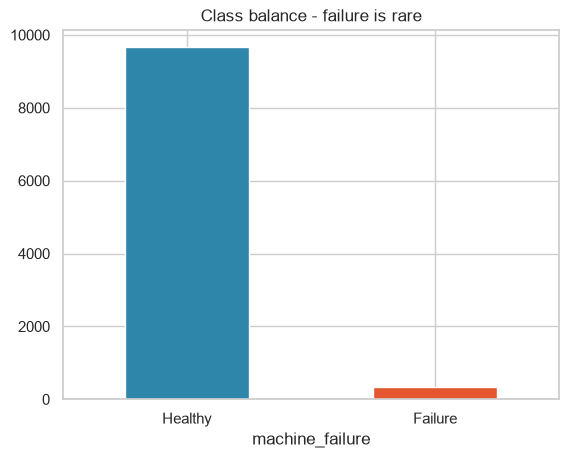

In [4]:
df = clean_ai4i(raw)
counts = df.machine_failure.value_counts()
print(counts)
print('imbalance 1 : %.0f' % (counts[0] / counts[1]))
ax = counts.plot(kind='bar', color=['#2E86AB', '#E4572E'], rot=0,
                 title='Class balance - failure is rare')
ax.set_xticklabels(['Healthy', 'Failure'])

## 1.3 Which sensor channels actually separate failures?

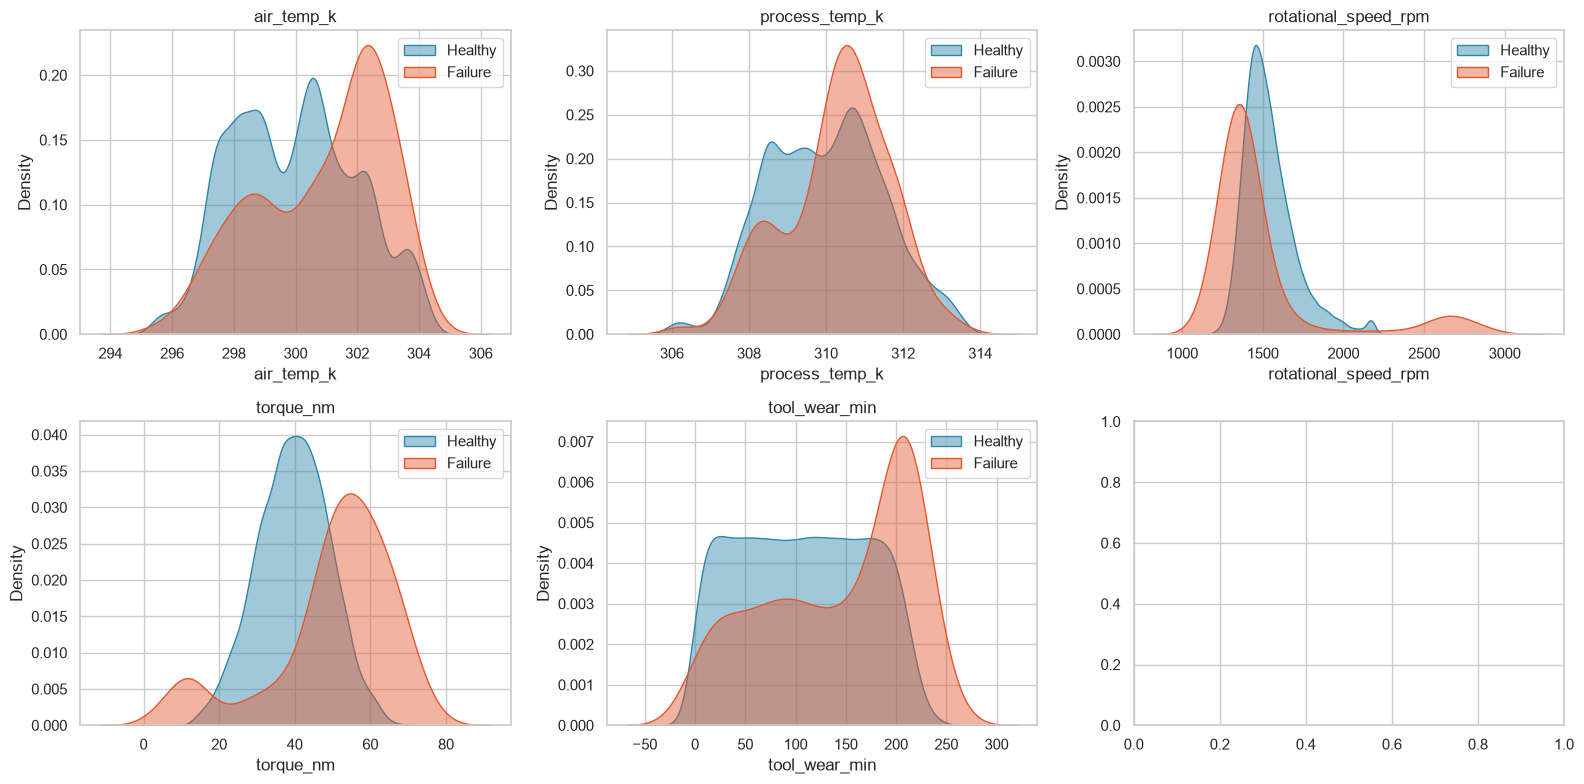

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), config.AI4I_SENSOR_COLUMNS):
    for lab, c, name in [(0, '#2E86AB', 'Healthy'), (1, '#E4572E', 'Failure')]:
        sns.kdeplot(df.loc[df.machine_failure == lab, col], ax=ax, fill=True,
                    alpha=.45, color=c, label=name, warn_singular=False)
    ax.set_title(col); ax.legend()
plt.tight_layout()

## 1.4 Failure modes: no single cause
Each labelled mode has a different physical signature - which is why we engineer features instead of throwing raw sensors at a model.

hdf_heat_dissipation_failure    115
osf_overstrain_failure           98
pwf_power_failure                95
twf_tool_wear_failure            46
rnf_random_failure               19
dtype: int64


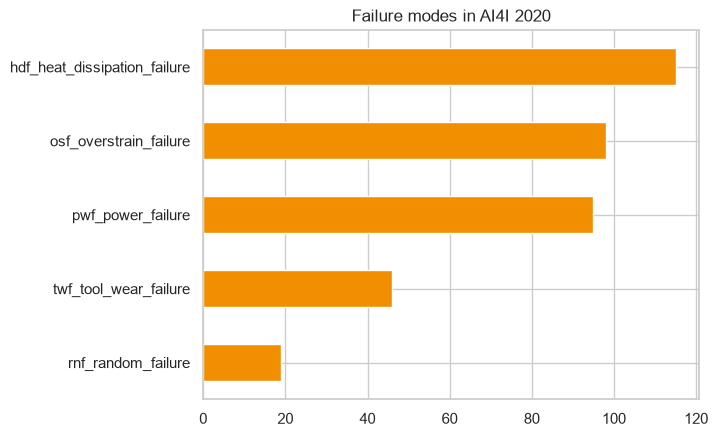

In [6]:
modes = df[config.AI4I_MODE_COLUMNS].sum().sort_values(ascending=False)
print(modes)
modes.plot(kind='barh', color='#F18F01', title='Failure modes in AI4I 2020')
plt.gca().invert_yaxis()

## 1.5 Takeaways
1. Failure is rare -> never trust accuracy.
2. Sensors overlap between classes -> single-threshold rules will fail.
3. Multiple failure modes -> need multi-feature models.

Next: `02_feature_engineering.ipynb`.